E-Commerce Sales & Customer Behaviour Analysis using Python

Project Overview

This project uses Python to analyse historical e-commerce transaction data and uncover insights related to sales performance, product demand, geographical revenue distribution, and customer purchasing behaviour.

Business Objectives
- Evaluate overall sales performance.
- Identify high-revenue products and markets.
- Analyse monthly sales trends.
- Understand customer purchasing behaviour.
- Measure repeat purchase activity.
- Develop data-driven business recommendations.
Tools & Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn and Google Colab.

Dataset

UCI Online Retail Dataset.

In [1]:
# Import libraries required for data analysis and visualization.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure the appearance of visualizations.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Display all columns when inspecting datasets.
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Upload the Excel dataset into Google Colab.

from google.colab import files

uploaded = files.upload()

# Identify the uploaded file.
file_name = next(iter(uploaded))

# Load the Excel file into a Pandas DataFrame.
df_raw = pd.read_excel(file_name)

print("Dataset loaded successfully!")

Saving Online Retail.xlsx to Online Retail.xlsx
Dataset loaded successfully!


In [3]:
# Display the first five records.
display(df_raw.head())

# Display the number of rows and columns.
print("Dataset dimensions:", df_raw.shape)

# Display column names.
print("\nColumn names:")
print(df_raw.columns.tolist())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Dataset dimensions: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [4]:
# Display information about columns and data types.
df_raw.info()

# Calculate missing values in each column.
print("\nMissing values:")
print(df_raw.isnull().sum())

# Check for duplicate records.
print("\nDuplicate records:", df_raw.duplicated().sum())

# Generate descriptive statistics.
display(df_raw.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate records: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


### Data Cleaning & Preparation

The original dataset contained 541,909 transaction records. Data preparation was performed using Pandas to improve data quality and ensure consistency.

The following steps were applied:

- Removed cancelled transactions.
- Excluded transactions with zero or negative quantities.
- Excluded transactions with zero or negative unit prices.
- Removed duplicate records.
- Converted invoice dates into datetime format.
- Handled missing product descriptions by assigning an "Unknown Product" label.
- Created a Revenue column by multiplying Quantity by UnitPrice.
- Extracted additional date attributes, including year, month, weekday and hour.

### Analysis Scope & Limitations

- Sales analysis focuses on positive-quantity transactions.
- Cancelled invoices and negative-quantity return transactions are excluded.
- Customer-level analysis includes only records with an available CustomerID.
- Revenue represents transaction-line sales value and does not account for shipping charges, refunds or other adjustments.
- The dataset covers December 2010 to December 2011, with December 2011 containing only partial-month data.

In [5]:
# Create a separate copy so the original dataset remains unchanged.
df = df_raw.copy()

# Remove leading and trailing spaces from column names.
df.columns = df.columns.str.strip()

# Convert invoice numbers to strings.
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

# Convert invoice dates into datetime format.
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Remove records without invoice numbers or valid dates.
df = df.dropna(subset=["InvoiceNo", "InvoiceDate"])

# Remove cancelled invoices.
df = df[~df["InvoiceNo"].str.startswith("C")]

# Keep only positive quantities.
df = df[df["Quantity"] > 0]

# Keep only positive unit prices.
df = df[df["UnitPrice"] > 0]

# Remove exact duplicate records.
df = df.drop_duplicates()

# Fill missing product descriptions.
df["Description"] = df["Description"].fillna("Unknown Product")

# Calculate revenue for each transaction line.
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Create additional date-related columns.
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["MonthName"] = df["InvoiceDate"].dt.strftime("%b")
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
df["Hour"] = df["InvoiceDate"].dt.hour

print("Data cleaning completed!")
print("Cleaned dataset dimensions:", df.shape)

Data cleaning completed!
Cleaned dataset dimensions: (524878, 15)


In [6]:
# Check whether cancelled invoices remain.
print(
    "Cancelled invoices:",
    df["InvoiceNo"].str.startswith("C").sum()
)

# Check for negative quantities.
print("Negative quantities:", (df["Quantity"] < 0).sum())

# Check for non-positive prices.
print("Non-positive prices:", (df["UnitPrice"] <= 0).sum())

# Check for duplicate records.
print("Duplicate records:", df.duplicated().sum())

# Check missing values.
print("\nRemaining missing values:")
print(df.isnull().sum())

Cancelled invoices: 0
Negative quantities: 0
Non-positive prices: 0
Duplicate records: 0

Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
Year                0
Month               0
MonthName           0
YearMonth           0
DayOfWeek           0
Hour                0
dtype: int64


In [7]:
# Calculate total sales revenue.
total_revenue = df["Revenue"].sum()

# Calculate total units sold.
total_units_sold = df["Quantity"].sum()

# Count unique invoices.
total_orders = df["InvoiceNo"].nunique()

# Count customers with an available CustomerID.
total_customers = df["CustomerID"].nunique()

# Calculate average order value.
average_order_value = total_revenue / total_orders

# Display the KPIs.
print("E-COMMERCE BUSINESS PERFORMANCE")
print("--------------------------------")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Units Sold: {total_units_sold:,.0f}")
print(f"Total Orders: {total_orders:,}")
print(f"Identified Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

E-COMMERCE BUSINESS PERFORMANCE
--------------------------------
Total Revenue: £10,642,110.80
Total Units Sold: 5,572,420
Total Orders: 19,960
Identified Customers: 4,338
Average Order Value: £533.17


,YearMonth,Revenue
0,2010-12-01,821452.730
1,2011-01-01,689811.610
2,2011-02-01,522545.560
3,2011-03-01,716215.260
4,2011-04-01,536968.491
5,2011-05-01,769296.610
6,2011-06-01,760547.010
7,2011-07-01,718076.121
8,2011-08-01,757841.380
9,2011-09-01,1056435.192


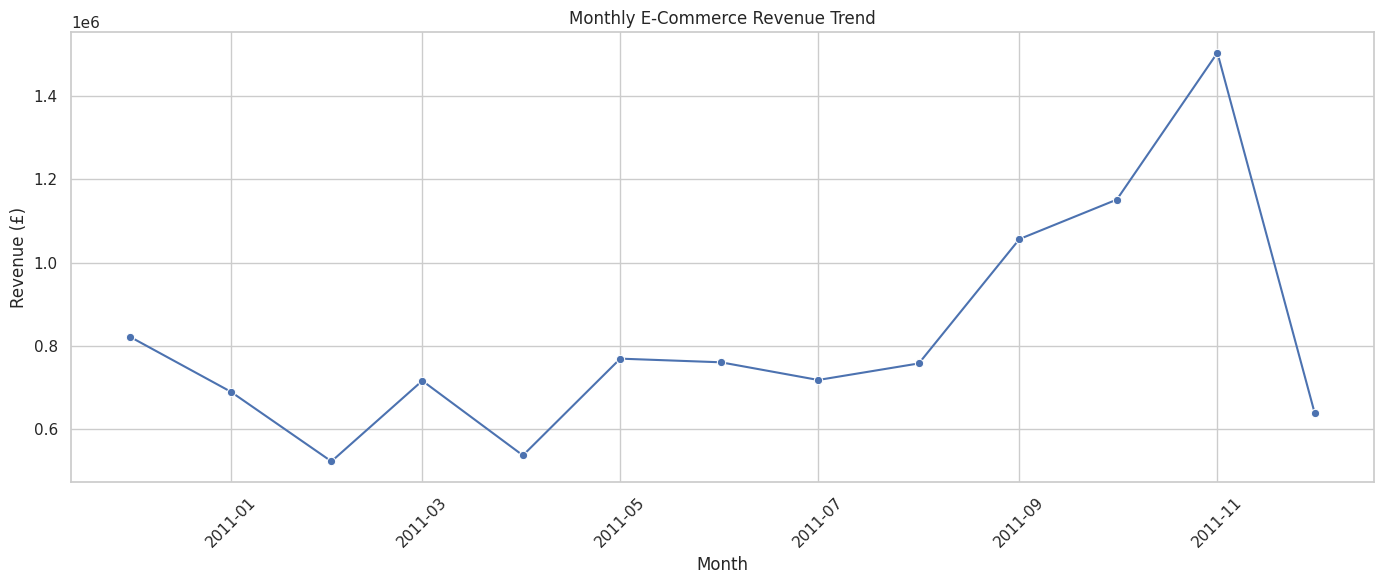

In [8]:
# Group revenue by month.
monthly_sales = (
    df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

# Convert monthly periods into timestamps for plotting.
monthly_sales["YearMonth"] = (
    monthly_sales["YearMonth"].dt.to_timestamp()
)

# Display monthly sales.
display(monthly_sales)

# Plot monthly revenue.
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly E-Commerce Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Description,Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
4,PARTY BUNTING,99445.23
5,JUMBO BAG RED RETROSPOT,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POSTAGE,78101.88
8,Manual,77752.82
9,RABBIT NIGHT LIGHT,66870.03


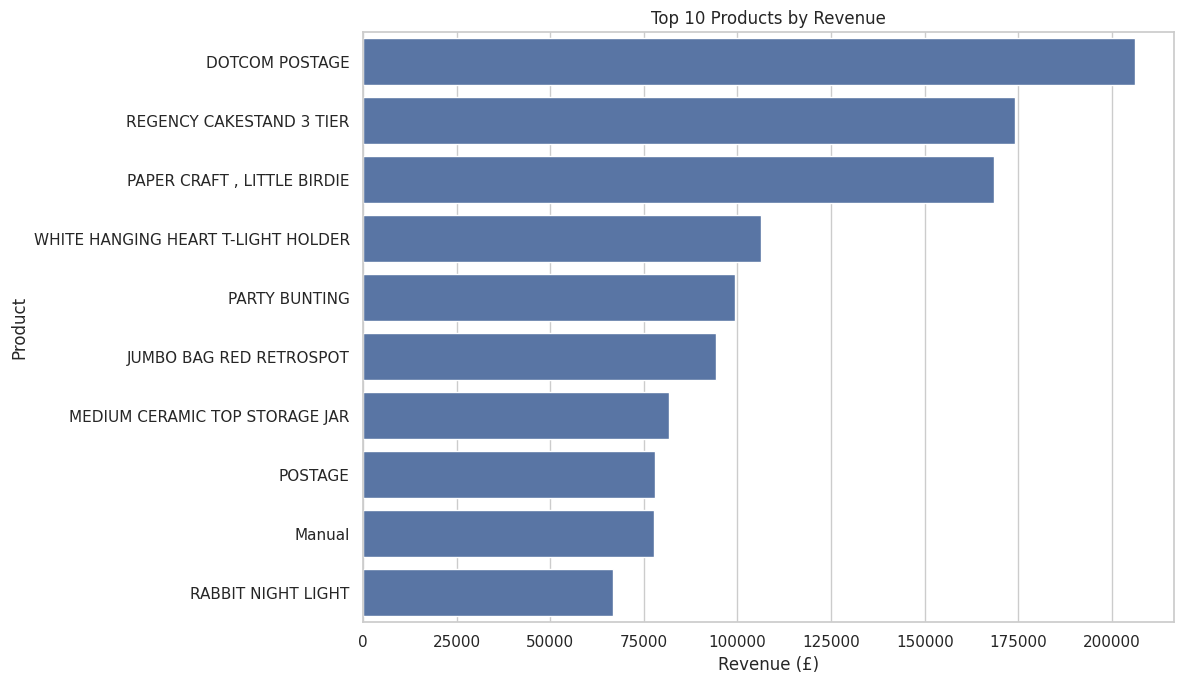

In [9]:
# Group revenue by product description.
top_products = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Display the top 10 products.
display(top_products)

# Create a horizontal bar chart.
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


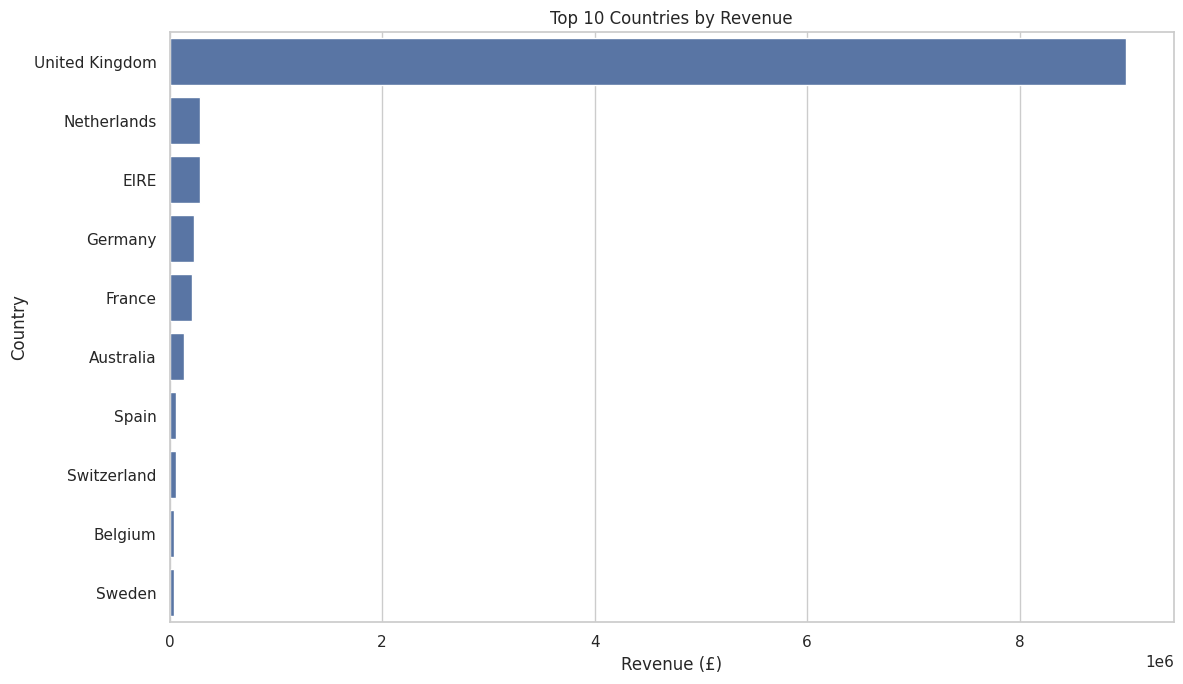

In [10]:
# Calculate revenue by country.
country_sales = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Display the top 10 countries.
display(country_sales)

# Visualize country revenue.
plt.figure(figsize=(12, 7))

sns.barplot(
    data=country_sales,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [18]:
# Remove transactions without customer IDs for customer analysis.
customer_data = df.dropna(subset=["CustomerID"]).copy()

# Convert CustomerID into whole numbers first,
# then into strings to remove unnecessary decimal places.
customer_data["CustomerID"] = (
    customer_data["CustomerID"].astype("int64").astype(str)
)

# Count unique invoices for each customer.
customer_orders = (
    customer_data.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index(name="TotalOrders")
)

# Identify repeat customers.
repeat_customers = customer_orders[
    customer_orders["TotalOrders"] >= 2
]

# Calculate total identified customers.
identified_customers = customer_orders["CustomerID"].nunique()

# Calculate repeat customers.
repeat_customer_count = repeat_customers["CustomerID"].nunique()

# Calculate repeat purchase rate.
repeat_purchase_rate = (
    repeat_customer_count / identified_customers
) * 100

print("CUSTOMER RETENTION ANALYSIS")
print("---------------------------")
print("Identified customers:", identified_customers)
print("Repeat customers:", repeat_customer_count)
print(f"Repeat purchase rate: {repeat_purchase_rate:.2f}%")

CUSTOMER RETENTION ANALYSIS
---------------------------
Identified customers: 4338
Repeat customers: 2845
Repeat purchase rate: 65.58%


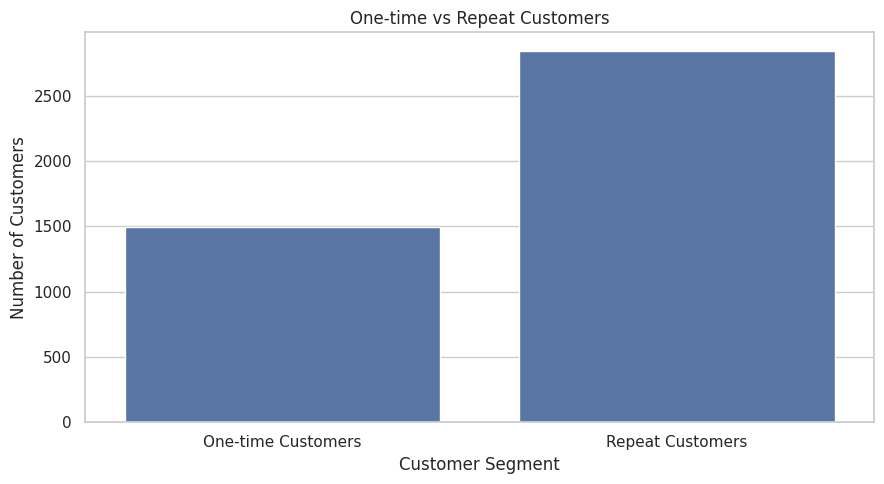

In [12]:
# Prepare repeat versus one-time customer counts.
customer_segments = pd.Series({
    "One-time Customers": identified_customers - repeat_customer_count,
    "Repeat Customers": repeat_customer_count
})

# Create a bar chart.
plt.figure(figsize=(9, 5))

sns.barplot(
    x=customer_segments.index,
    y=customer_segments.values
)

plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

,DayOfWeek,Revenue
0,Monday,1775782.071
1,Tuesday,2175700.511
2,Wednesday,1847074.380
3,Thursday,2199292.570
4,Friday,1837470.491
5,Saturday,0.000
6,Sunday,806790.781


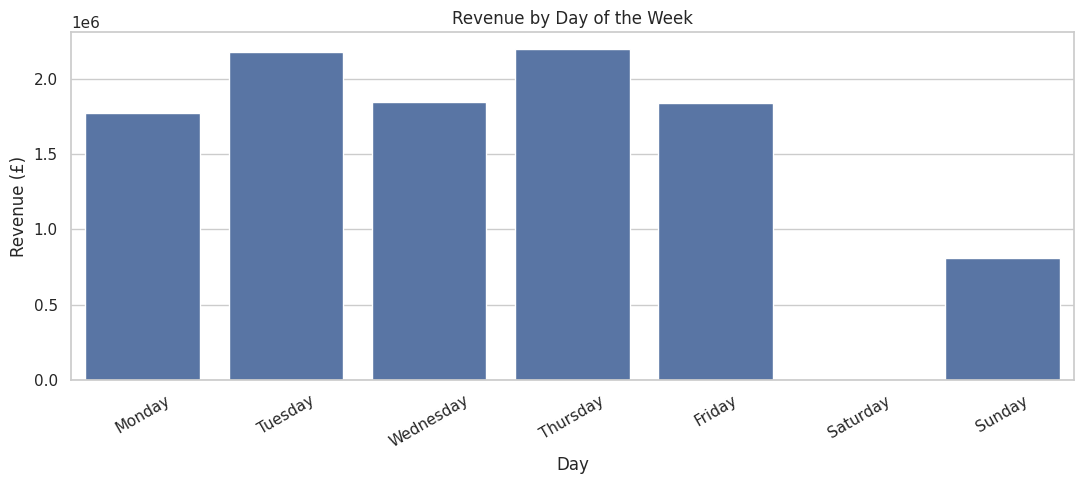

In [17]:
# Calculate revenue by day of the week.
weekday_sales = (
    df.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ], fill_value=0)
    .reset_index()
)

# Replace any remaining missing revenue values with zero.
weekday_sales["Revenue"] = weekday_sales["Revenue"].fillna(0)

# Display weekday revenue.
display(weekday_sales)

# Plot weekday revenue.
plt.figure(figsize=(11, 5))

sns.barplot(
    data=weekday_sales,
    x="DayOfWeek",
    y="Revenue"
)

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

,CustomerID,Revenue
0,14646,280206.02
1,18102,259657.30
2,17450,194390.79
3,16446,168472.50
4,14911,143711.17
5,12415,124914.53
6,14156,117210.08
7,17511,91062.38
8,16029,80850.84
9,12346,77183.60


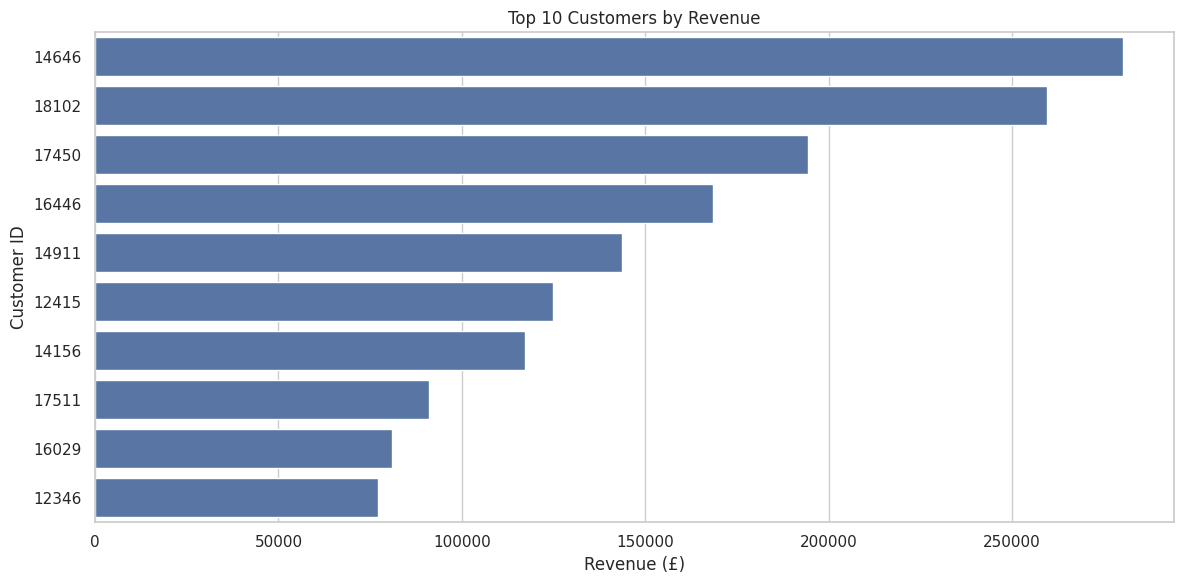

In [19]:
# Calculate total revenue generated by each customer.
top_customers = (
    customer_data.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Display the top 10 customers.
display(top_customers)

# Visualize the top customers.
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="Revenue",
    y="CustomerID"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

,Description,Revenue
0,REGENCY CAKESTAND 3 TIER,174156.54
1,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
3,PARTY BUNTING,99445.23
4,JUMBO BAG RED RETROSPOT,94159.81
5,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
6,RABBIT NIGHT LIGHT,66870.03
7,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
8,ASSORTED COLOUR BIRD ORNAMENT,58927.62
9,CHILLI LIGHTS,54096.36


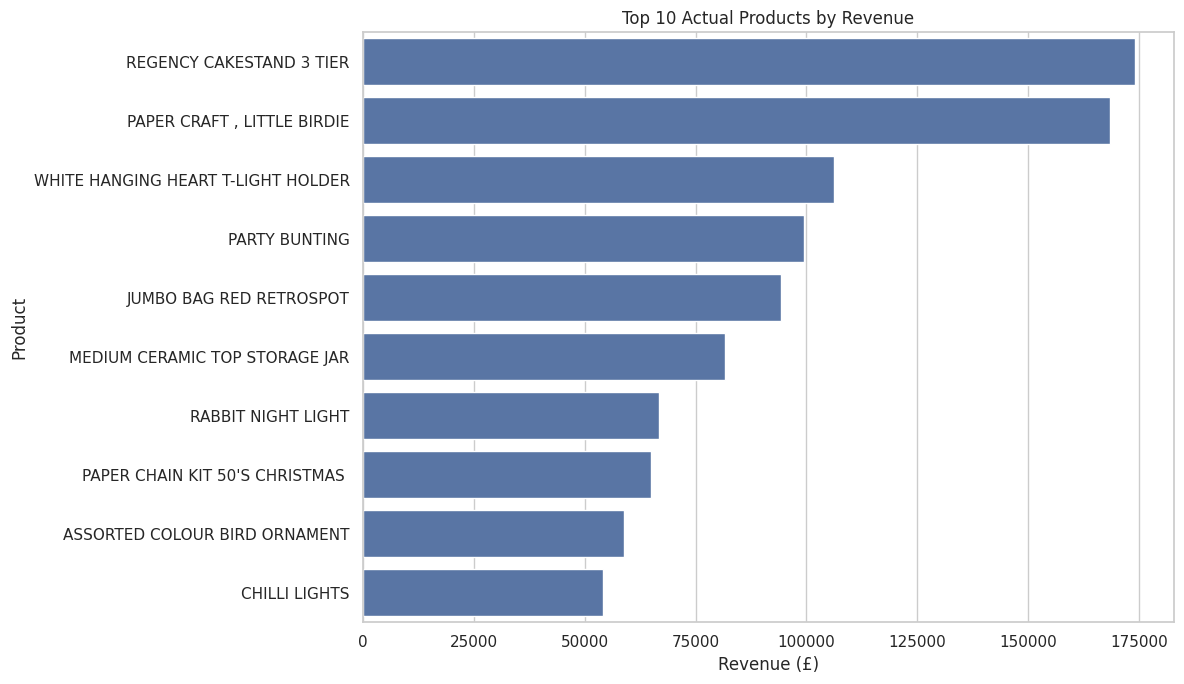

In [21]:
# Exclude non-product transaction descriptions from product analysis.
excluded_items = [
    "POSTAGE",
    "DOTCOM POSTAGE",
    "MANUAL"
]

# Create a dataset containing only actual products.
product_data = df[
    ~df["Description"].str.upper().isin(excluded_items)
].copy()

# Calculate revenue generated by each actual product.
top_10_actual_products = (
    product_data.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Display the top 10 actual products.
display(top_10_actual_products)

# Create a horizontal bar chart.
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_actual_products,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Actual Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


In [22]:

# Export the cleaned transaction data.
df.to_csv("cleaned_online_retail.csv", index=False)

# Export monthly sales analysis.
monthly_sales.to_csv("monthly_sales_analysis.csv", index=False)

# Export the improved top 10 actual product analysis.
top_10_actual_products.to_csv("top_products_analysis.csv", index=False)

# Export country performance.
country_sales.to_csv("country_sales_analysis.csv", index=False)

# Export customer order counts.
customer_orders.to_csv("customer_purchase_analysis.csv", index=False)

print("Analysis files exported successfully!")


Analysis files exported successfully!


In [16]:
from google.colab import files

files.download("monthly_sales_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

# Import the Google Colab file download utility.
from google.colab import files

# Download the analysis output files.
files.download("monthly_sales_analysis.csv")
files.download("top_products_analysis.csv")
files.download("country_sales_analysis.csv")
files.download("customer_purchase_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Business Insights & Recommendations

### Key Business Insights

**1. Strong Revenue Concentration in the United Kingdom**

The United Kingdom contributes approximately £9 million in revenue, making it the dominant market in the dataset.

**2. November Shows Strong Sales Performance**

November 2011 recorded the highest monthly revenue, at approximately £1.50 million. This indicates a significant sales peak during the month.

**3. Repeat Customers Represent a Significant Segment**

Approximately 65.58% of identified customers made two or more purchases during the dataset period. This highlights the importance of maintaining customer relationships and encouraging repeat purchases.

**4. Product Revenue Varies Across the Catalogue**

The top-product analysis identifies products generating the highest transaction revenue, helping the business understand which products contribute most to sales.

### Business Recommendations

- **Customer Retention:** Develop loyalty campaigns and personalised promotions to encourage repeat purchases.
- **Seasonal Planning:** Prepare inventory and marketing campaigns ahead of November's observed sales peak.
- **Market Diversification:** Explore opportunities to expand sales beyond the United Kingdom while maintaining the existing customer base.
- **Product Strategy:** Prioritise inventory planning and promotional decisions using product-level revenue performance.

### Conclusion

This analysis demonstrates how Python can be used to transform raw e-commerce transaction data into meaningful business insights. The project covers data preparation, exploratory data analysis, sales performance measurement, customer purchasing behaviour and data visualisation.